In [1]:
#%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import config
import general
import contraction
import constantes
import profiles

import pandas as pd

from scipy.integrate import quad

In [2]:
plt.rcParams['axes.labelsize'] = 20  
plt.rcParams['xtick.labelsize'] = 18   
plt.rcParams['ytick.labelsize'] = 18

XLIM = (20, 210)
YLIM = (1e-6, 1e-1)
FIGSIZE = (10,10)

In [3]:
halo = general.contract_halo()

# Convert the simulated radius from Mpc/h back to physical kpc
r_kpc = (halo['r'] / constantes.H) * 1000.0
rf_kpc = (halo['r_f'] / constantes.H) * 1000.0

dm = halo['dm_profile']
bar = halo['baryon_profile']
cnt = halo['contraction']
rho_baryons = halo['rho_stars'] + halo['rho_gas']

# Calculate Abell 1703 Observational Truth [20 - 210 kpc]
r_s_kpc = 727.0
alpha = 1.09
c200 = 3.1
r_cut_cd_kpc = 30.0 
sigma_0_cd = 299.4
G_kpc = 4.30091e-6

r_kpc_obs = np.linspace(20, 210, 500)

# Normalizations
rho_0_dpie_kpc = (sigma_0_cd**2) / (2 * np.pi * G_kpc)

def gnfw_integrand(x, alpha_val):
    return (x**2) / ((x**alpha_val) * (1 + x)**(3 - alpha_val))

integral_val, _ = quad(gnfw_integrand, 0, c200, args=(alpha,))


# Equations and params used by Marceau
z_cluster = 0.28
H0 = 70.0
Omega_m = 0.3
Omega_L = 0.7

Hz_kpc = (H0 / 1000.0) * np.sqrt(Omega_m * (1 + z_cluster)**3 + Omega_L)
rho_crit_z = (3 * Hz_kpc**2) / (8 * np.pi * G_kpc)
rho_s_kpc = (200.0 / 3.0) * rho_crit_z * (c200**3) / integral_val

#Baryons density 
density_cd_pc = (rho_0_dpie_kpc / ((r_kpc_obs**2) * (1 + (r_kpc_obs / r_cut_cd_kpc)**2))) / 1e9 
x = r_kpc_obs / r_s_kpc
# density_cd_pc = (rho_0_dpie_kpc / ((config.R**2) * (1 + (config.R / r_cut_cd_kpc)**2))) / 1e9 
# x = config.R / r_s_kpc
# NFW used
density_gnfw_pc = (rho_s_kpc / ((x**alpha) * (1 + x)**(3 - alpha))) / 1e9  

In [ ]:
# Mask for the contracted dark matter
rf_clean = rf_kpc[1:]
rho_contracted_clean = halo['rho_dm_contracted'][1:]
valid_rf = rf_clean >= 20

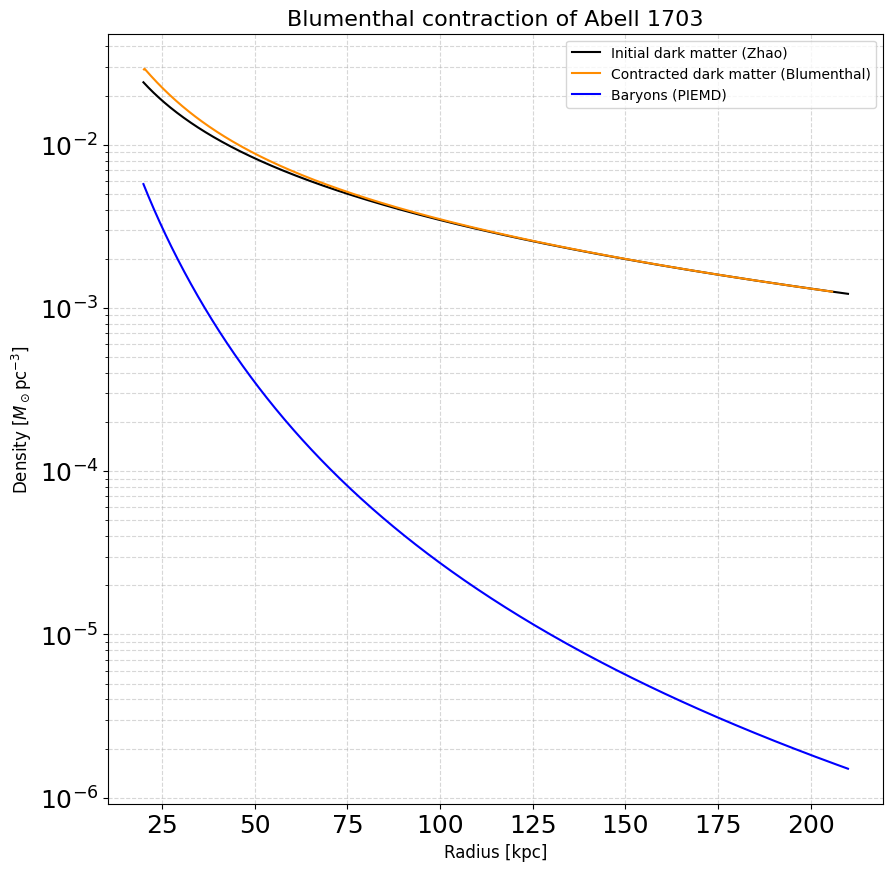

In [5]:
plt.figure(figsize=FIGSIZE)
plt.semilogy(r_kpc, halo['rho_dm_initial'] , label=f'Initial dark matter ({dm})', color='black')
plt.semilogy(rf_clean[valid_rf], rho_contracted_clean[valid_rf], label=f'Contracted dark matter ({cnt})', color='darkorange')
plt.semilogy(r_kpc, rho_baryons , label=f'Baryons ({bar})', color='blue')

# Plot Observational Truth (Abell 1703)
# plt.semilogy(r_kpc_obs, density_gnfw_pc, label=f'Abell 1703 dark matter', color='purple', ls='--', linewidth=2.5)
# plt.semilogy(r_kpc_obs, density_cd_pc, label=f'Abell 1703 baryons ', color='magenta', ls='--', linewidth=2.5)

plt.title(f"{cnt.capitalize()} contraction of Abell 1703", fontsize=16)
plt.xlabel(r'Radius [kpc]', fontsize=12)
plt.ylabel(r'Density [$M_\odot \mathrm{pc}^{-3}$]', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()

### Contrairement au stage il n'y a pas de croisement car ce ne sont pas les mêmes masses de halos et densité 